# 10 — Candle resampling: daily ↔ weekly ↔ monthly

*Extension: min / max price · code: `src/sp500/candles.py`*

**Downsampling** aggregates daily candles into weekly and monthly candles. **Upsampling** maps those bigger candles back onto every day so that each day only sees candles that were already closed, plus the candle that is still forming (week-to-date, month-to-date).

← previous: [`09_candlestick_patterns.ipynb`](09_candlestick_patterns.ipynb) · next: [`11_range_features_targets.ipynb`](11_range_features_targets.ipynb) →

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT / "src"), str(ROOT)]   # project package + root scripts

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "font.size": 10})

In [2]:
from sp500.config import DATA_PROCESSED
from sp500.candles import resample_candles, partial_candle, upsample_to_daily, multi_timeframe_features
from sp500.plots import plot_candles

daily = pd.read_parquet(DATA_PROCESSED / "sp500_daily.parquet")
ohlc = daily[["gspc_open", "gspc_high", "gspc_low", "gspc_close"]].loc["1962-07":].dropna()
ohlc.columns = ["open", "high", "low", "close"]

## 1. Daily → weekly / monthly

open = first open, high = max high, low = min low, close = last close. A candle is dated on its **last trading day**, the day it becomes known.

In [3]:
weekly = resample_candles(ohlc, "W")
monthly = resample_candles(ohlc, "M")
print(f"{len(ohlc):,} daily -> {len(weekly):,} weekly -> {len(monthly):,} monthly candles")
week = ohlc.loc["2026-10-12":"2026-10-16"]
display(week)
display(weekly.loc["2026-10-16":"2026-10-16"])
assert np.isclose(weekly.loc["2026-10-16", "high"], week["high"].max())

16,148 daily -> 3,351 weekly -> 772 monthly candles


,open,high,low,close
date,,,,
2026-10-12,7813.0400,7821.6699,7796.9399,7807.2402
2026-10-13,7795.2700,7814.1499,7786.1099,7805.4502
2026-10-14,7774.1802,7789.1499,7693.3101,7718.9399
2026-10-15,7687.3101,7754.1499,7669.6602,7744.0601
2026-10-16,7745.3198,7756.8398,7631.7700,7659.4399


,open,high,low,close
date,,,,
2026-10-16,7813.04,7821.6699,7631.77,7659.4399


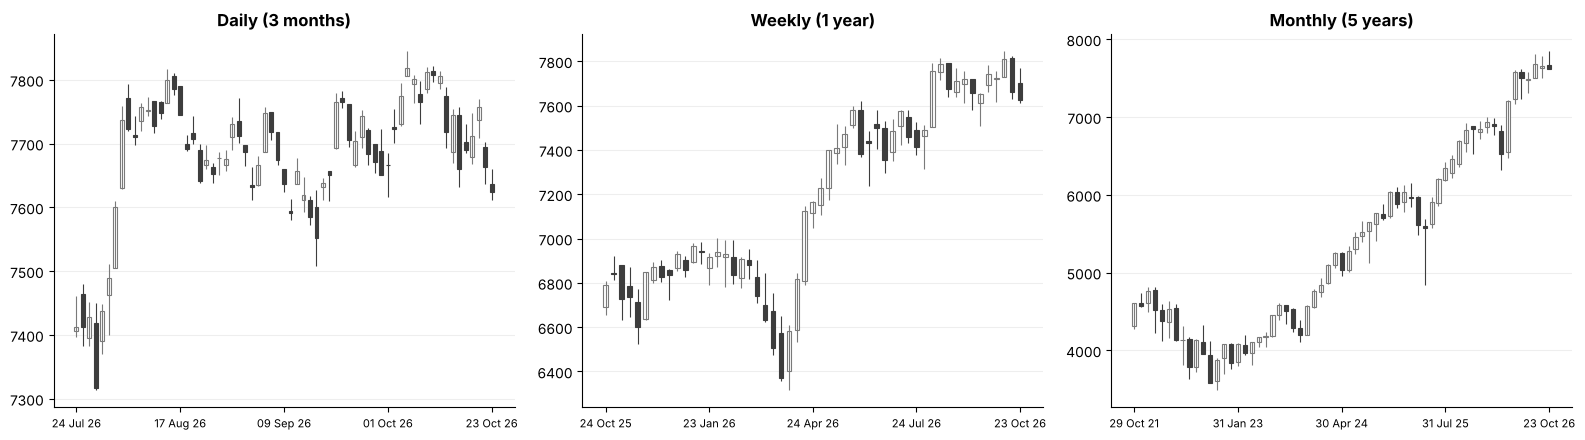

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (title, c) in zip(axes, [("Daily (3 months)", ohlc.loc["2026-07-24":]),
                                 ("Weekly (1 year)", weekly.loc["2025-10-24":]),
                                 ("Monthly (5 years)", monthly.loc["2021-10":])]):
    plot_candles(ax, c, n_ticks=4); ax.set_title(title)
plt.tight_layout(); plt.show()

## 2. Upsampling back to daily, without look-ahead

For each day: the **previous closed** weekly candle (forward-filled, shifted one day so the current week never leaks into "previous") and the **week-to-date** candle.

In [5]:
part = partial_candle(ohlc, "W")
prev = upsample_to_daily(weekly, ohlc.index).shift(1)
demo = pd.DataFrame({
    "day high": ohlc["high"], "week-to-date high": part["high"], "week-to-date low": part["low"],
    "prev week high": prev["high"], "prev week low": prev["low"]}).loc["2026-10-09":"2026-10-23"]
demo

,day high,week-to-date high,week-to-date low,prev week high,prev week low
date,,,,,
2026-10-09,7820.5698,7844.5200,7727.5898,7754.6699,7616.7798
2026-10-12,7821.6699,7821.6699,7796.9399,7844.5200,7727.5898
2026-10-13,7814.1499,7821.6699,7786.1099,7844.5200,7727.5898
2026-10-14,7789.1499,7821.6699,7693.3101,7844.5200,7727.5898
2026-10-15,7754.1499,7821.6699,7669.6602,7844.5200,7727.5898
2026-10-16,7756.8398,7821.6699,7631.7700,7844.5200,7727.5898
2026-10-19,7731.1802,7731.1802,7684.7900,7821.6699,7631.7700
2026-10-20,7748.4199,7748.4199,7668.0298,7821.6699,7631.7700
2026-10-21,7770.3999,7770.3999,7668.0298,7821.6699,7631.7700


Monday 12 Oct still sees the week of 5–9 Oct as "previous" and starts a new week-to-date candle; the week-to-date high only ever grows with days already seen.

In [6]:
mtf = multi_timeframe_features(ohlc)
cut = "2015-06-17"
diff = (mtf.loc[:cut] - multi_timeframe_features(ohlc.loc[:cut])).abs().max()
assert (diff.fillna(0) < 1e-12).all(), diff[diff > 1e-12]
print(f"OK: {mtf.shape[1]} multi-timeframe features, identical on truncated data")
mtf.tail()

OK: 18 multi-timeframe features, identical on truncated data


,w_prev_range,w_prev_body,w_range_avg8,w_pattern_score,w_dist_prev_high,w_dist_prev_low,w_td_range,w_td_ret,w_td_pos,m_prev_range,m_prev_body,m_range_avg8,m_pattern_score,m_dist_prev_high,m_dist_prev_low,m_td_range,m_td_ret,m_td_pos
date,,,,,,,,,,,,,,,,,,
2026-10-19,0.024578,-0.019855,0.018374,-1.0,-0.016882,0.007696,0.006018,-0.001564,0.128044,0.035899,0.002102,0.056338,0.0,-0.011822,0.024077,0.029462,0.003159,0.324713
2026-10-20,0.024578,-0.019855,0.018374,-1.0,-0.014047,0.010532,0.010429,0.001271,0.554048,0.035899,0.002102,0.056338,0.0,-0.008986,0.026913,0.029462,0.005995,0.420611
2026-10-21,0.024578,-0.019855,0.018374,-1.0,-0.008281,0.016298,0.013262,0.007038,0.870763,0.035899,0.002102,0.056338,0.0,-0.003220,0.032679,0.029462,0.011761,0.616448
2026-10-22,0.024578,-0.019855,0.018374,-1.0,-0.020438,0.004140,0.017270,-0.005120,0.195958,0.035899,0.002102,0.056338,0.0,-0.015378,0.020521,0.029462,-0.000397,0.204840
2026-10-23,0.024578,-0.019855,0.018374,-1.0,-0.025639,-0.001061,0.020587,-0.010321,0.073330,0.035899,0.002102,0.056338,0.0,-0.020579,0.015321,0.030080,-0.005597,0.049948


## 3. Do bigger candles carry information about the next week's range?

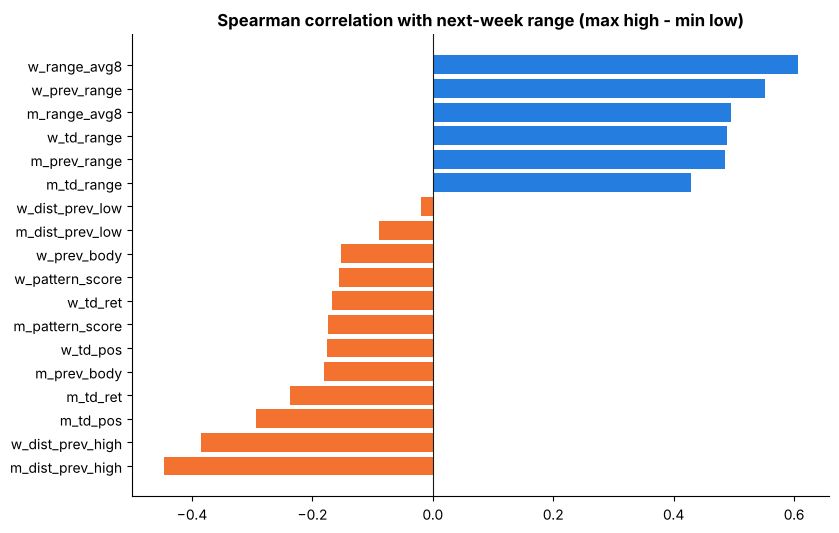

In [7]:
from sp500.range_data import forward_extremes
fx = forward_extremes(daily.loc[ohlc.index], 5)
rng = (fx["up_5"] - fx["down_5"]).rename("next-week range")
corr = mtf.join(rng).corr(method="spearman")["next-week range"].drop("next-week range").sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(corr.index, corr.values, color=np.where(corr > 0, "#257de0", "#f47230"))
ax.set_title("Spearman correlation with next-week range (max high - min low)")
ax.axvline(0, color="#191919", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Result.** The range of last week's / last month's candle and of the week-to-date candle are strongly related to the size of the coming range (volatility clusters), which is why these features rank high in the XGBoost / CatBoost importances.